# Capstone: Define and Solve an ML Problem

In [1]:
import pandas as pd
import numpy as np
import os 
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import tensorflow.keras as keras
from sklearn.preprocessing import StandardScaler
import time

**Note**: As you work through the notebook, you can import additional packages as needed.

## Overview


In this capstone assignment, you will follow the machine learning life cycle and implement one of the supervised learning models you have learned so far in this course, along with a neural network, to solve a predictive problem.

This capstone spans two lab sessions.

- **Unit 5 Lab:** You will define a machine learning problem, explore and prepare your data, and train, test, evaluate and improve a traditional machine learning model (Parts 1–5).
- **Unit 6 Lab:** After completing Unit 6 on neural networks, you will apply a neural network to the same problem and compare the two approaches (Parts 6–7).

There is a checkpoint at the end of Part 5 that marks where to stop during the Unit 5 lab.

You will complete the following:

1. Choose your Data Set and Build Your DataFrame
2. Define Your ML Problem
3. Understand Your Data
4. Prepare Your Data
5. Train, Test, Evaluate and Improve a Traditional Machine Learning Model *(Unit 5 lab)*
6. Train, Test, Evaluate and Improve Neural Network *(Unit 6 lab)*
7. Compare Your Models and Reflect *(Unit 6 lab)*

**This is an individual assignment.** You are welcome to discuss ideas with your peers, but the code and written responses you submit must be your own.

**Note:** This capstone is intentionally less scaffolded than your weekly labs; that is by design. You are expected to make your own implementation choices, add code cells as needed, and document your reasoning throughout.

## Part 1: Choose Your Data Set and Build Your DataFrame


You will choose one of two data sets to work with for this capstone. In both cases, you will be solving a supervised learning binary classification problem by predicting one of two possible class labels. Both data sets have been used earlier in the course, so you are already familiar with their structure. 

**Option A: Census Income Data** (`censusData.csv`)
This data set contains demographic and employment information from the 1994 U.S. Census. You will use it to predict whether an individual's annual income exceeds $50,000. Your label column is `income_binary`, which contains two values: `<=50K` and `>50K`. You will need to convert this column into a binary numeric label (for example, 0 and 1) during data preparation.

**Option B: Airbnb NYC Listings Data** (`airbnbListingsData.csv`)
This data set contains information about Airbnb listings in New York City. You will use it to predict whether a listing is high-priced. The data set includes a new `price_category` column that classifies each listing as either "high price" or "low price" based on whether the listing’s price falls above or below the 75th percentile of all listing prices. Listings at or above the 75th percentile are labeled as `high`, while the remaining listings are labeled as `low`. You will need to convert this column into a binary numeric label (for example, 0 and 1) during data preparation.

**Note:**  These versions of the data sets differ slightly from the versions you have worked with in this program. For example, they may not include some of the preprocessing necessary for specific models. 

#### Load a Data Set and Save it as a Pandas DataFrame

The code cell below contains filenames (path + filename) for the two data sets available to you.

<b>Task:</b> In the code cell below, load your chosen data set using `pd.read_csv()` and save it to a DataFrame named `df`. Then call `df.head()` to inspect the first few row of the data set.

In [2]:
# File paths for both data sets
census_filename = os.path.join(os.getcwd(), "data_capstone", "censusData.csv")
airbnb_filename = os.path.join(os.getcwd(), "data_capstone", "airbnbListingsData.csv")

# Load your chosen dataset and save it to df
df = pd.read_csv(census_filename)

print(df.shape)
df.head(10)

(32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex_selfID,capital-gain,capital-loss,hours-per-week,native-country,income_binary
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Non-Female,2174,0,40.0,United-States,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Non-Female,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Non-Female,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Non-Female,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K
5,37.0,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40.0,United-States,<=50K
6,49.0,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16.0,Jamaica,<=50K
7,52.0,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Non-Female,0,0,45.0,United-States,>50K
8,31.0,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50.0,United-States,>50K
9,42.0,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Non-Female,5178,0,40.0,United-States,>50K


## Part 2: Define Your ML Problem

The first step of the machine learning life cycle involves defining your business problem. In the markdown cell below, you will clearly define what you are trying to predict and why it matters. 

<b>Task</b>: In the markdown cell below, answer all of the following questions:

1. Which data set did you choose?
2. What is your label? What are you predicting?
3. What features do you plan to use? (This list may change after you explore your data.)
5. Why does this problem matter? Using the business brief you read in the lab overview page, explain how the organization described there could use a model that predicts this label to create value or inform decisions for their client.

1. I chose option A and converted the Census Income data set into a DataFrame.
2. The label is income_binary. The model should predict whether or not an individual makes above 50k a year.
3. The rest of the columns will be the features.
4. Currently, the company is manually going through the data and reviewing applicant's information to determine if they are elligible for the program. This is time-consuming, inconsistent, and leaves room for bias that an ML model could be trained to avoid. This then allows the client to go through applications more effectively once a model ensures an applicant is likely to actually qualify for their programs.

## Part 3: Understand Your Data

Now that you have defined your problem, perform exploratory data analysis (EDA) with that problem in mind. Consider the following as you inspect your data:

1. What data preparation techniques would you like to use? These data preparation techniques may include:

    * handling missing values
    * finding and replacing outliers
    * performing feature engineering techniques such as one-hot encoding on categorical features
    * selecting appropriate features and removing irrelevant features
    * addressing class imbalance


2. What machine learning model would you like to use that is suitable for your predictive problem and data?
   * You may use one of the following models that you have worked with so far:
        - K-Nearest Neighbors (KNN)
        - Decision Tree
        - Logistic Regression
   * Are there other data preparation techniques that you will need to apply to build a balanced modeling data set for your problem and model? For example, will you need to scale your data?
 

3. How will you evaluate and improve the model's performance?
    * Are there specific evaluation metrics or methods that are appropriate for your problem, dataset, or selected model?
    
<b>Task</b>: In the code cells below, use the techniques you have learned in this course to inspect and analyze your data.

<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

### Class Imbalance

Examine the distribution of your label column to determine whether class imbalance is present. Use at least one visualization to show the class distribution. In the **EDA Summary** below, you will discuss how you plan to address any observed imbalance during data preparation.

<=50K    24720
>50K      7841
Name: income_binary, dtype: int64


<AxesSubplot:xlabel='income_binary', ylabel='count'>

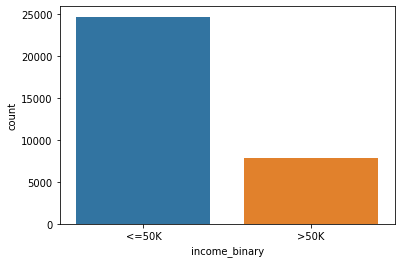

In [3]:
print(df['income_binary'].value_counts())
sns.countplot(x=df['income_binary'])

### Inspect and Analyze Your Data

Explore your features. Use summary statistics and visualizations to understand how your features are distributed and how they relate to the label. Identify issues such as missing values, outliers, or a feature that is irrelevant or redundant.

Think of the different techniques you have used to inspect and analyze your data in this course. These include using Pandas to apply data filters, using the Pandas `describe()` method to get insight into key statistics for each column, using the Pandas `dtypes` property to inspect the data type of each column, and using Matplotlib and Seaborn to detect outliers and visualize relationships between features and labels. 

Use at least one plot that visualizes a relationship between features and the label.

In [4]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32399.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32236.000000
mean,38.589216,1.897784e+05,10.080679,615.907773,87.303830,40.450428
std,13.647862,1.055500e+05,2.572720,2420.191974,402.960219,12.353748
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,14084.000000,4356.000000,99.000000


In [5]:
df.dtypes

age               float64
workclass          object
fnlwgt              int64
education          object
education-num       int64
marital-status     object
occupation         object
relationship       object
race               object
sex_selfID         object
capital-gain        int64
capital-loss        int64
hours-per-week    float64
native-country     object
income_binary      object
dtype: object

In [6]:
for col in df.columns:
    print(str(col) + ': ' + str(df[col].nunique()))

age: 73
workclass: 8
fnlwgt: 21648
education: 16
education-num: 16
marital-status: 7
occupation: 14
relationship: 6
race: 5
sex_selfID: 2
capital-gain: 106
capital-loss: 92
hours-per-week: 94
native-country: 41
income_binary: 2


In [7]:
df.groupby('relationship')['marital-status'].unique()

relationship
Husband                     [Married-civ-spouse, Married-AF-spouse]
Not-in-family     [Never-married, Divorced, Married-spouse-absen...
Other-relative    [Married-civ-spouse, Never-married, Separated,...
Own-child         [Never-married, Divorced, Married-civ-spouse, ...
Unmarried         [Never-married, Divorced, Separated, Widowed, ...
Wife                        [Married-civ-spouse, Married-AF-spouse]
Name: marital-status, dtype: object

In [8]:
df.groupby('education')['education-num'].unique()

education
10th             [6]
11th             [7]
12th             [8]
1st-4th          [2]
5th-6th          [3]
7th-8th          [4]
9th              [5]
Assoc-acdm      [12]
Assoc-voc       [11]
Bachelors       [13]
Doctorate       [16]
HS-grad          [9]
Masters         [14]
Preschool        [1]
Prof-school     [15]
Some-college    [10]
Name: education-num, dtype: object

<AxesSubplot:xlabel='capital-gain', ylabel='Count'>

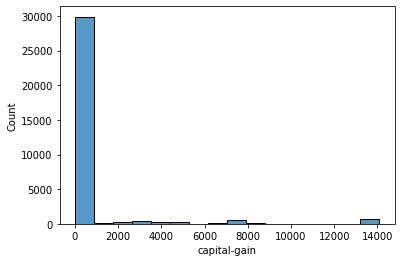

In [9]:
sns.histplot(df['capital-gain'])

<AxesSubplot:xlabel='capital-loss', ylabel='Count'>

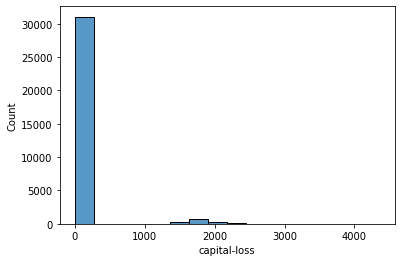

In [10]:
sns.histplot(df['capital-loss'])

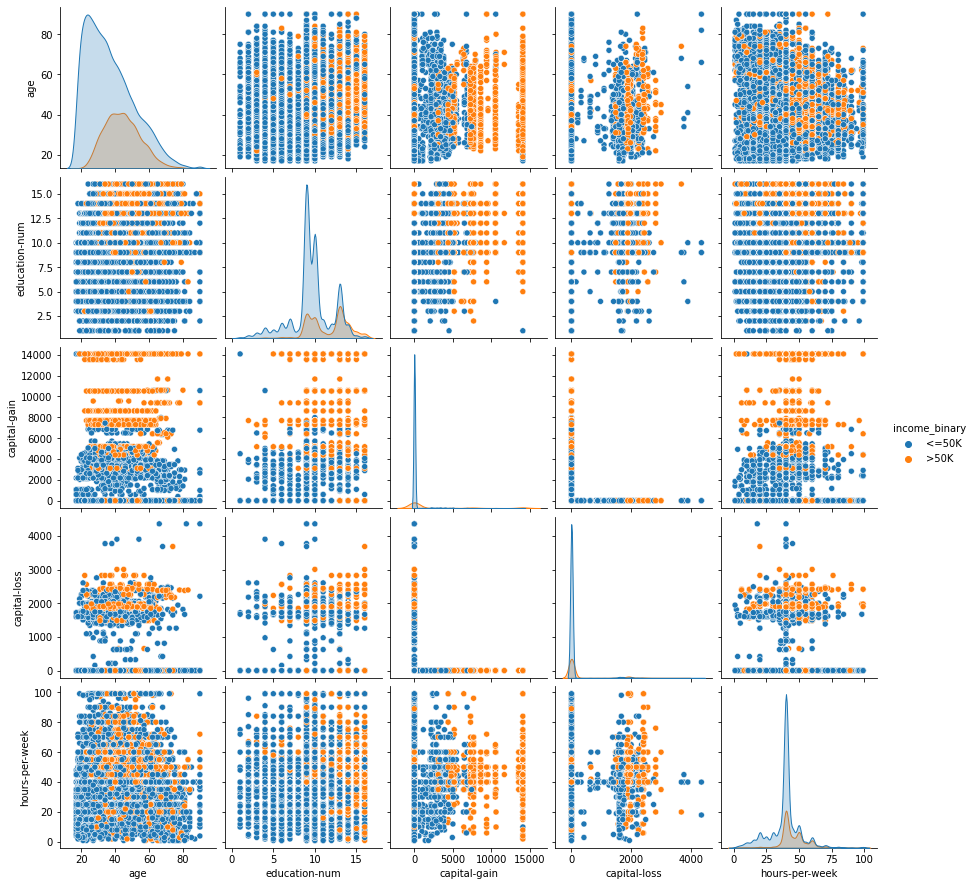

In [11]:
sns.pairplot(df[['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'income_binary']], hue='income_binary')

(array([0, 1, 2, 3, 4, 5, 6]),
 [Text(0, 0, 'Never-married'),
  Text(1, 0, 'Married-civ-spouse'),
  Text(2, 0, 'Divorced'),
  Text(3, 0, 'Married-spouse-absent'),
  Text(4, 0, 'Separated'),
  Text(5, 0, 'Married-AF-spouse'),
  Text(6, 0, 'Widowed')])

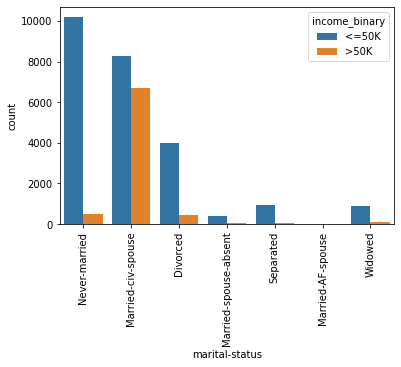

In [12]:
sns.countplot(x = df['marital-status'], hue = df['income_binary'])
plt.xticks(rotation = 90)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15]),
 [Text(0, 0, 'Bachelors'),
  Text(1, 0, 'HS-grad'),
  Text(2, 0, '11th'),
  Text(3, 0, 'Masters'),
  Text(4, 0, '9th'),
  Text(5, 0, 'Some-college'),
  Text(6, 0, 'Assoc-acdm'),
  Text(7, 0, 'Assoc-voc'),
  Text(8, 0, '7th-8th'),
  Text(9, 0, 'Doctorate'),
  Text(10, 0, 'Prof-school'),
  Text(11, 0, '5th-6th'),
  Text(12, 0, '10th'),
  Text(13, 0, '1st-4th'),
  Text(14, 0, 'Preschool'),
  Text(15, 0, '12th')])

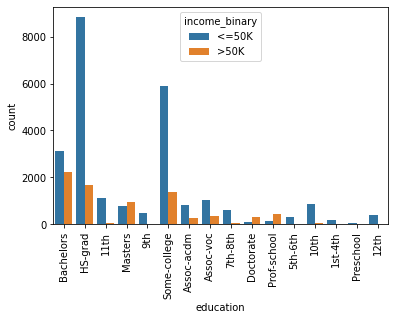

In [13]:
sns.countplot(x = df['education'], hue = df['income_binary'])
plt.xticks(rotation = 90)

(array([0, 1]), [Text(0, 0, 'Non-Female'), Text(1, 0, 'Female')])

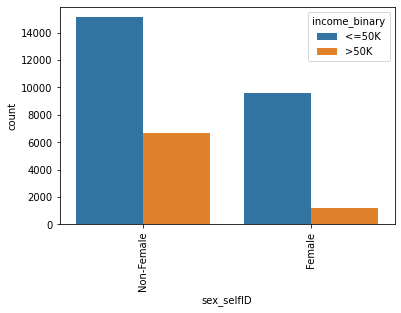

In [14]:
sns.countplot(x = df['sex_selfID'], hue = df['income_binary'])
plt.xticks(rotation = 90)

(array([0, 1, 2, 3, 4, 5]),
 [Text(0, 0, 'Not-in-family'),
  Text(1, 0, 'Husband'),
  Text(2, 0, 'Wife'),
  Text(3, 0, 'Own-child'),
  Text(4, 0, 'Unmarried'),
  Text(5, 0, 'Other-relative')])

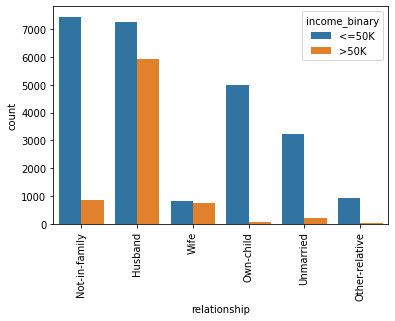

In [15]:
sns.countplot(x = df['relationship'], hue = df['income_binary'])
plt.xticks(rotation = 90)

In [16]:
df['sex_selfID'].value_counts()

Non-Female    21790
Female        10771
Name: sex_selfID, dtype: int64

In [17]:
df['race'].value_counts()

White                 27816
Black                  3124
Asian-Pac-Islander     1039
Amer-Indian-Inuit       311
Other                   271
Name: race, dtype: int64

In [18]:
df['native-country'].value_counts()

United-States                 29170
Mexico                          643
Philippines                     198
Germany                         137
Canada                          121
Puerto-Rico                     114
El-Salvador                     106
India                           100
Cuba                             95
England                          90
Jamaica                          81
South                            80
China                            75
Italy                            73
Dominican-Republic               70
Vietnam                          67
Guatemala                        64
Japan                            62
Poland                           60
Columbia                         59
Taiwan                           51
Haiti                            44
Iran                             43
Portugal                         37
Nicaragua                        34
Peru                             31
France                           29
Greece                      

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'White'),
  Text(1, 0, 'Black'),
  Text(2, 0, 'Asian-Pac-Islander'),
  Text(3, 0, 'Amer-Indian-Inuit'),
  Text(4, 0, 'Other')])

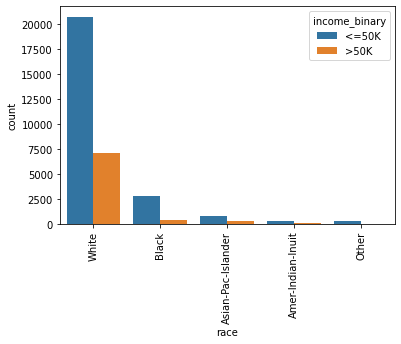

In [19]:
sns.countplot(x = df['race'], hue = df['income_binary'])
plt.xticks(rotation = 90)

In [20]:
df.isna().sum()

age                162
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex_selfID           0
capital-gain         0
capital-loss         0
hours-per-week     325
native-country     583
income_binary        0
dtype: int64

In [21]:
(df['workclass'].isna() == df['occupation'].isna()).sum()

32554

In [22]:
df.duplicated().sum()

22

### EDA Summary

<b>Task</b>: In the markdown cell below, summarize the key findings from your data exploration. Describe any patterns, anomalies, or data quality issues you identified and explain how those findings may influence your data preparation decisions. For example, your exploration may affect how you handle missing values, address class imbalance, or determine which features to keep or remove.

- There is a class imbalance with about a 75/25 split between the two labels.
- Missing Values: very few rows missing age, hours-per-week, or native-country. More MVs in workclass and occupation and those overlap exactly.
- Pairplots: age and education-num show clear split between the peaks for each label. Less so with hours-per-week. Capital gains/losses were mostly zero so it was hard to tell on the diagonol but clear split seen on other charts.
- Categorical data: Education, sex_selfID, and marital-status have strong connection, but education and education-num 1 to 1 mapping, redundant.
- Only 22 duplicates
- Imbalance between in sex_selfID (70/30 non-female/female) and race (~85/15 white/other)

### Ethical Considerations:

Machine learning models can cause harm when they reflect or amplify biases in the data they are trained on. 

<b>Task</b>: In the markdown cell below, answer both of the following questions:

1. What biases or ethical concerns might be present in your dataset? Think about who collected the data, how it was collected, and which groups of people appear in it. Are there features in the dataset that could serve as proxies for protected characteristics like race, gender, or socioeconomic status?
2. Who could be harmed by a model that makes incorrect predictions on this data, and how? Be specific about which groups are most at risk and what the real-world consequences of errors might look like.

1. Race and sex_selfID are really imbalanced, which could represent biases in how the data was collected and which populations were targeted in the data collection. One feature that could be used as a proxy for gender would be certain categories within relationship status (husband == non-female, wife == female). Because there's less examples for female/non-white, this could result in the model being poorly trained and show bias in the predictions. 
2. Because the model is being used to determine who qualifies for certain loans/benefits, innacurately predicting someone earning >50k when they are actually in the <=50k group would be most harmful as those in genuine need of loans would be denied/disqualified. Because of the imbalance in sex_selfID (skewed proportion in females earning >50k:<=50k compared to nonfemale >50k:<=50K), the model would be less likely to predict a female as earning >50k, even if she had similar qualifications to a man earning >50k. This would mean that women are more likely to qualify for the program even if they shouldn't based on their actual income, expending resources and harming the company in the long run.

## Part 4: Prepare Your Data

<b>Task</b>: In the code cell below, prepare your data for modeling. The specific steps you take will depend on what you found during your EDA and which model you plan to use. 

<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

In [23]:
df.isna().sum()

age                162
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex_selfID           0
capital-gain         0
capital-loss         0
hours-per-week     325
native-country     583
income_binary        0
dtype: int64

In [24]:
df = df.dropna(subset = ['age'])
df = df.dropna(subset = ['native-country'])
df = df.dropna(subset = ['hours-per-week'])
df['workclass'] = df['workclass'].fillna('Unknown')
df['occupation'] = df['occupation'].fillna('Unknown')
df.isna().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex_selfID        0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income_binary     0
dtype: int64

In [25]:
df = df.drop_duplicates()
df.duplicated().sum()

0

In [26]:
df['sex_selfID'] = (df['sex_selfID'] == 'Female').astype(int)
df['income_binary'] = (df['income_binary'] == '>50K').astype(int)

In [27]:
df['native-country'] = (df['native-country'] == 'United-States').astype(int)
df['native-country'].nunique()

2

In [28]:
to_encode = ['workclass', 'marital-status', 'occupation', 'relationship', 'race']
for col in to_encode:
    df_col = pd.get_dummies(df[col], prefix=col + '_')
    df = df.join(df_col)
    df.drop(columns = col, inplace=True)

In [29]:
features = df.columns.drop(['income_binary', 'education', 'fnlwgt'])
features

Index(['age', 'education-num', 'sex_selfID', 'capital-gain', 'capital-loss',
       'hours-per-week', 'native-country', 'workclass__Federal-gov',
       'workclass__Local-gov', 'workclass__Never-worked', 'workclass__Private',
       'workclass__Self-emp-inc', 'workclass__Self-emp-not-inc',
       'workclass__State-gov', 'workclass__Unknown', 'workclass__Without-pay',
       'marital-status__Divorced', 'marital-status__Married-AF-spouse',
       'marital-status__Married-civ-spouse',
       'marital-status__Married-spouse-absent',
       'marital-status__Never-married', 'marital-status__Separated',
       'marital-status__Widowed', 'occupation__Adm-clerical',
       'occupation__Armed-Forces', 'occupation__Craft-repair',
       'occupation__Exec-managerial', 'occupation__Farming-fishing',
       'occupation__Handlers-cleaners', 'occupation__Machine-op-inspct',
       'occupation__Other-service', 'occupation__Priv-house-serv',
       'occupation__Prof-specialty', 'occupation__Protective-s

In [30]:
df.head(10)

,age,fnlwgt,education,education-num,sex_selfID,capital-gain,capital-loss,hours-per-week,native-country,income_binary,...,relationship__Not-in-family,relationship__Other-relative,relationship__Own-child,relationship__Unmarried,relationship__Wife,race__Amer-Indian-Inuit,race__Asian-Pac-Islander,race__Black,race__Other,race__White
0,39.0,77516,Bachelors,13,0,2174,0,40.0,1,0,...,1,0,0,0,0,0,0,0,0,1
1,50.0,83311,Bachelors,13,0,0,0,13.0,1,0,...,0,0,0,0,0,0,0,0,0,1
2,38.0,215646,HS-grad,9,0,0,0,40.0,1,0,...,1,0,0,0,0,0,0,0,0,1
3,53.0,234721,11th,7,0,0,0,40.0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,28.0,338409,Bachelors,13,1,0,0,40.0,0,0,...,0,0,0,0,1,0,0,1,0,0
5,37.0,284582,Masters,14,1,0,0,40.0,1,0,...,0,0,0,0,1,0,0,0,0,1
6,49.0,160187,9th,5,1,0,0,16.0,0,0,...,1,0,0,0,0,0,0,1,0,0
7,52.0,209642,HS-grad,9,0,0,0,45.0,1,1,...,0,0,0,0,0,0,0,0,0,1
8,31.0,45781,Masters,14,1,14084,0,50.0,1,1,...,1,0,0,0,0,0,0,0,0,1
9,42.0,159449,Bachelors,13,0,5178,0,40.0,1,1,...,0,0,0,0,0,0,0,0,0,1


### Data Preparation Summary:

<b>Task</b>: In the markdown cell below, document the data preparation steps you took. For each decision, explain why you made it. For example, why did you handle missing values the way you did? Why did you keep or remove certain features? If a preparation step depends on the model you selected (for example, scaling for KNN but not for a decision tree), explain that as well.

- Dropped rows with missing values in age, native-country, and hours-per-week because those were very few in the entire dataset. For workclass and occupation replaced null values with 'Unknown' - a new category the model could handle/work with. Dropped duplicate examples because very few of them and not worth risking inflated accuracy scores if split between training and testing sets
- Switched sex_selfID and income_binary to binary columns with 1 being female and >50k (0/1 much easier for a model to work with)
- Using native country as US/other because US heavily heavily overrepresented. That'll be switched to binary as well with US being 1, again because binary is easier for a model work with.
- one hot encoding for workclass, marital-status, occupation, relationship, race
- Made feature list excluding the label, id, and education (overlaps with education-num and harder to work with than numerical data)

## Part 5: Train, Test, Evaluate, and Improve a Traditional Machine Learning Model

Now you will train, test and evaluate your model. You will also use model selection techniques to improve your model's performance by identifying the optimal hyperparameter configuration.

<b>Task</b>: In the code cells below, do the following:

1. Create labeled examples from the dataset
2. Create training and test sets out of the labeled examples 
3. Train, test and evaluate your model 
    * You must evaluate your model using accuracy and F1 score. Use `accuracy_score` and `f1_score` from `sklearn.metrics`. For the F1 score, use `average='binary'` since this is a binary classification problem. You will compare your model's performance to that of a neural network later in this capstone. Save the results of your evaluation metrics to variables for later comparison.
    * You may use additional evaluation metrics of your choosing.
4. Perform model selection through grid search cross-validation to identify optimal hyperparameter values for your model
5. Train, test and evaluate a final version of your model using the optimal hyperparameter configuration.
6. Interpret your model's outputs in the context of the business problem. Depending on the model you chose, this might mean:
    * KNN: Describe what your model's performance metrics tell you about its behavior. For example: How does accuracy change as you vary k? What does that suggest about the structure of your data?
    * Decision Tree: print or plot feature importances.
    * Logistic Regression: print or plot the model coefficients.



<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

In [31]:
# Create labeled examples from the dataset
X = df[features]
y = df['income_binary']
print(X.shape)
print(y.shape)

(31476, 49)
(31476,)


In [32]:
# Create training and test sets out of the labeled examples 
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state = 123)

In [33]:
# Train, test and evaluate your model
model = LogisticRegression(max_iter = 5000)
model.fit(X_train, y_train)

class_label_predictions = model.predict(X_test)
acc_score = accuracy_score(y_test, class_label_predictions)
f1 = f1_score(y_test, class_label_predictions, average = 'binary')
print(acc_score)
print(f1)

0.8481414804617177
0.6598671726755218


In [34]:
# Perform model selection through grid search cross-validation (GridSearchCV)
# to identify optimal hyperparameter values for your model
print('Running ...')
cs = [10**i for i in range(-5, 5)]
param_grid = {'C': cs}
grid = GridSearchCV(model, param_grid, cv = 5)
grid_search = grid.fit(X_train, y_train)
best_C = grid_search.best_estimator_.C
print('Done')
print(best_C)

Running ...
Done
0.1


In [35]:
# Train, test and evaluate a final version of your model using the optimal hyperparameter values.
model_best = LogisticRegression(C = best_C, max_iter = 5000)
model_best.fit(X_train, y_train)
class_label_predictions_best = model_best.predict(X_test)
acc_score_best = accuracy_score(y_test, class_label_predictions_best)
f1_best = f1_score(y_test, class_label_predictions_best, average = 'binary')
print(acc_score_best)
print(f1_best)

0.8467647993222492
0.6524141244294981


In [36]:
# Interpret your model's outputs 
coefficients = pd.Series(model_best.coef_[0], index=X_train.columns)
coefficients.sort_values(ascending=False)

relationship__Wife                       0.919512
occupation__Exec-managerial              0.686621
occupation__Prof-specialty               0.467460
marital-status__Married-civ-spouse       0.461026
occupation__Tech-support                 0.353911
occupation__Protective-serv              0.290265
education-num                            0.254958
workclass__Federal-gov                   0.074479
marital-status__Married-AF-spouse        0.066450
occupation__Sales                        0.058714
hours-per-week                           0.025969
age                                      0.022413
capital-loss                             0.000649
capital-gain                             0.000347
workclass__Never-worked                 -0.003267
occupation__Armed-Forces                -0.016160
native-country                          -0.023042
workclass__Without-pay                  -0.048847
occupation__Priv-house-serv             -0.183298
workclass__Self-emp-inc                 -0.225256


### Model Reflection:

<b>Task</b>: In the markdown cell below, answer the following questions:

1. Which model did you choose and why? Reference your problem and data characteristics in your explanation.
2. What did you learn through the model selection process?
3. How do you interpret your model's outputs? What do the predictions or coefficients or feature importances actually mean in the context of your problem?
4. Are there any fairness or ethical concerns with your model? Who might be harmed by incorrect predictions, and are any groups more likely to be affected?

1. I chose a Logistic Regression model because from the data exploration stage, it showed that many features had linear/direct relationships with the label (the pairplots were fairly linear). The label is also binary, so logistic regression works well (vs if it were a regression problem). The coefficients also show how much of an impact the different features have, which would help the client understand the ml model and use that information for their decision-making. 
2. The grid search selected the best c value of 0.1, although the default was trained with c=1. However, the accuracy of model_best was actually slightly lower than the default (.8467 vs .8481). The f1 score was also lower for model_best than default (.6524 vs .6598). This showed that maybe the scores won't always give the full picture of which is the better performing model, considering the best c was picked by judging a much larger training set and then tested on just one test set, so maybe overall c=0.1 would still perform better in general but just on that specific test set, c=1 slightly outperformed model_best. I also raised the number of max interations after receiving error messages.
3. The coefficients show that marital-status/relationship and occupation have a strong correlation to the label. Specifically examples with those that are married or working in executive position has a large positive coefficient, meaning likely to be predicted as earning above 50K. On the other end of the spectrum, being unmarried/never married has a large negative coefficient, meaning those examples are more likely to earn under 50K. Hours-per-week, age, and capital gain/loss has very little impact on the prediction, with those coefficients near 0.
4. Certain racial categorization (Black, AAPI) have a large negative correlation, as well as sex_selfID (female) so examples with these traits are more likely to be predicted as earning under 50K. This shows bias in the data that trained the model and potentially bias in how it predicts similar examples. Minority groups are most affected by this due to the limited data on these groups. Those that would be most harmed would be people belonging to minority groups that earn above 50K, as they'd be wrongly labeled as earning under 50K, which would hurt if the model was used for something other than determining if someone qualifies for a loan or program that's meant to benefit those earning under 50K. Based on the current business problem, this issue in the model would actually hurt the company more, expending resources to those who don't really qualify.

---
## ✔️ Unit 5 Checkpoint

**Stop here.** If you have completed Parts 1 through 5, you are done with the Unit 5 portion of this capstone.

Parts 6 and 7 require you to train and evaluate a neural network. You will learn about neural networks in the Unit 6 asynchronous content. Do not start Part 6 until you have completed that material and your lab facilitator has directed you to continue. Do not submit your work for grading until you complete Parts 6 and 7.

Make sure your notebook is saved before you close it.

---
## Part 6: Train, Test, Evaluate and Improve a Neural Network

> **⚠️ Before you write any code in Part 6, do this first.**
> 
> Your notebook does not retain variables between sessions. All of your variables and everything else need to be restored to memory before any code below will work.
> 
> Go to **Kernel > Restart & Run All** to re-run Parts 1 through 5, then scroll back here to continue. If you skip this step, you will see a `NameError` on the first code cell below.

Now you will apply a neural network to the same problem and dataset. You will use Keras to build a feedforward neural network for binary classification.

The scaffolding below will walk you through the steps. Where you see a **Task**, fill in the code. Where you see a **Decision**, you are making an independent choice about your architecture or training process. For each decision, add a comment explaining what you chose and why.


### Prepare Your Data for the Neural Network

Neural networks require all input features to be numeric and scaled. If your features are on very different scales (for example, one feature ranges from 0 to 90 and another from 0 to 99999), the model may train less effectively and have difficulty learning meaningful patterns from the data.

Before training your network, create scaled versions of your training and test data. Use `StandardScaler()` from `sklearn.preprocessing` to standardize your features: 

<b>Task</b>: Complete the code cell below to fit the scaler on your training data, then transform both training and test sets. Save the results to new variables (for example, `X_train_scaled` and `X_test_scaled`) so your original data remains available for reference.

**Note:** Use your scaled data for all neural network steps below.

In [37]:
# Scale your data for the neural network

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform the training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler to transform the test data
X_test_scaled = scaler.transform(X_test)

### Step 1: Define Your Model Architecture

You will use the Keras `Sequential` class to build your network. Your network should have:

- An input layer with the correct shape for your data
- At least two hidden layers using the `Dense` class
- An output layer appropriate for binary classification

<b>Task:</b> Create a `Sequential` model object and name it `nn_model`. Then construct and add each layer.

**Decision:** How many hidden layers will you use? How many units in each? What activation function will you use for the hidden layers? Add a comment explaining your choices.

In [38]:
# Get the number of features in your training data
n_features = X_train_scaled.shape[1]

# Create the neural network model
nn_model = keras.Sequential()

# Create the input layer and add the input layer to the 'nn_model' object
input_layer = keras.layers.InputLayer(input_shape=(len(X_train.columns),), name='input')
nn_model.add(input_layer)

# Create the hidden layers and add the hidden layers to the 'nn_model' object
# Decision: How many layers? How many units? What activation function?
# The problem and features are all fairly simple/linear and there isn't that much data, so I'll stick with just two hidden layers to prevent training an overfit model.
# Will use relu because there aren't any negative values in the features so don't need to worry about dead neurons.
# Will use 32-16 units, don't need more because not many features and not many examples.
hidden_layer_1 = keras.layers.Dense(units=32, activation='relu')
nn_model.add(hidden_layer_1)

hidden_layer_2 = keras.layers.Dense(units=16, activation='relu')
nn_model.add(hidden_layer_2)


# Create the output layer and add the output layer to the 'nn_model' object
# Use the correct number of units and activation function for binary classification
output_layer = keras.layers.Dense(units=1, activation='sigmoid') 
nn_model.add(output_layer)

# Print a summary of your model
nn_model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 32)                1600      
_________________________________________________________________
dense_1 (Dense)              (None, 16)                528       
_________________________________________________________________
dense_2 (Dense)              (None, 1)                 17        
Total params: 2,145
Trainable params: 2,145
Non-trainable params: 0
_________________________________________________________________


### Step 2:  Define the Optimization Function

<b>Task:</b> In the code cell below, create an optimizer object. Use stochastic gradient descent (SGD) with a learning rate of your choosing.

**Decision:** What learning rate will you use? Add a comment explaining your choice.

In [39]:
# Decision: What learning rate will you use? Add a comment explaining your decision.
# Learning rate = 0.1 for simple model with uncomplicated data, converge faster

sgd_optimizer = keras.optimizers.SGD(learning_rate=0.1)

### Step 3: Define the Loss Function

<b>Task:</b> In the code cell below, create a binary cross entropy loss function using `keras.losses.BinaryCrossentropy()`. Use  the parameter `from_logits=False`. 

In [40]:
loss_fn = keras.losses.BinaryCrossentropy(from_logits=False)

### Step 4: Compile the Model

<b>Task:</b> In the code cell below, package the network architecture with the optimizer and the loss function using the `compile()` method. Use the `accuracy` evaluation metric.

In [41]:
nn_model.compile(optimizer = sgd_optimizer,loss = loss_fn, metrics = ['accuracy'])

### Step 5: Fit the Model to the Training Data

We will define our own callback class to output information from our model while it is training. Make sure you execute the code cell below so that it can be used in subsequent cells.

In [42]:
class ProgBarLoggerNEpochs(keras.callbacks.Callback):
    
    def __init__(self, num_epochs: int, every_n: int = 50):
        self.num_epochs = num_epochs
        self.every_n = every_n
    
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n == 0:
            s = 'Epoch [{}/ {}]'.format(epoch + 1, self.num_epochs)
            logs_s = ['{}: {:.4f}'.format(k.capitalize(), v)
                      for k, v in logs.items()]
            s_list = [s] + logs_s
            print(', '.join(s_list))


<b>Task:</b> Use the `fit()` method to fit your model to the training data. Save the result to variable `history.`

Use the `validation_split` parameter to reserve a portion of your training data for validation during training (a common choice is `validation_split=0.2`). After each epoch, the model is evaluated on this validation data, allowing you to monitor how well the model generalizes and helping you detect overfitting.

Also, use the the logger class defined above to track training progress.

**Decision:** How many epochs will you train for? Add a comment explaining your choice.

**Note:** This may take a while to run.

In [43]:
# Decision: How many epochs? Add a comment.
# fewer epochs to prevent overfitting with limited data

t0 = time.time() # start time

num_epochs = 50

history = nn_model.fit(
    X_train_scaled,
    y_train,
    epochs = num_epochs,
    verbose = 0,
    callbacks = [ProgBarLoggerNEpochs(num_epochs,every_n=5)],
    validation_split = 0.2) 

t1 = time.time() # stop time

print('Elapsed time: %.2fs' % (t1-t0))

Epoch [5/ 50], Loss: 0.3006, Accuracy: 0.8608, Val_loss: 0.3187, Val_accuracy: 0.8518
Epoch [10/ 50], Loss: 0.2927, Accuracy: 0.8622, Val_loss: 0.3224, Val_accuracy: 0.8486
Epoch [15/ 50], Loss: 0.2870, Accuracy: 0.8650, Val_loss: 0.3238, Val_accuracy: 0.8514
Epoch [20/ 50], Loss: 0.2825, Accuracy: 0.8676, Val_loss: 0.3243, Val_accuracy: 0.8521
Epoch [25/ 50], Loss: 0.2789, Accuracy: 0.8706, Val_loss: 0.3263, Val_accuracy: 0.8484
Epoch [30/ 50], Loss: 0.2751, Accuracy: 0.8712, Val_loss: 0.3235, Val_accuracy: 0.8521
Epoch [35/ 50], Loss: 0.2727, Accuracy: 0.8721, Val_loss: 0.3313, Val_accuracy: 0.8545
Epoch [40/ 50], Loss: 0.2695, Accuracy: 0.8744, Val_loss: 0.3324, Val_accuracy: 0.8507
Epoch [45/ 50], Loss: 0.2671, Accuracy: 0.8729, Val_loss: 0.3354, Val_accuracy: 0.8482
Epoch [50/ 50], Loss: 0.2650, Accuracy: 0.8740, Val_loss: 0.3369, Val_accuracy: 0.8498
Elapsed time: 33.85s


### Step 6: Visualize Training Performance

<b>Task:</b>  

Create two plots to visualize the model's performance over time:
1. Training loss and validation loss over epochs, on the same axes.
2. Training accuracy and validation accuracy over epochs, on the same axes.

Label your axes and include a legend.

Use the `history` object returned by `fit()` to obtain this information. 



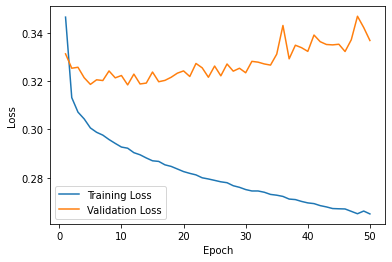

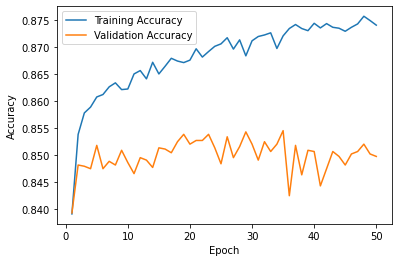

In [44]:
# Plot training loss and validation loss over epochs
plt.plot(range(1, num_epochs + 1), history.history['loss'], label='Training Loss')
plt.plot(range(1, num_epochs + 1), history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Plot training accuracy and validation accuracy over epochs
plt.plot(range(1, num_epochs + 1), history.history['accuracy'], label='Training Accuracy')
plt.plot(range(1, num_epochs + 1), history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

### Step 7: Evaluate the Model's Performance on the Test Set

<b>Task:</b> Use your neural network to generate predictions on the test set and evaluate its performance using accuracy and F1 score. Use `nn_model.predict()` to generate predictions. Since `nn_model.predict()` returns probabilities, apply a threshold of 0.5 to convert probabilities into binary class predictions before computing your metrics. Save your accuracy and F1 score results to clearly named variables so you can compare them to the results from your previous model. Print the results.

In [45]:
# Generate predictions from your neural network using your scaled test data
# nn_model.predict() returns probabilities — apply a threshold of 0.5 to get class labels

nn_probs = nn_model.predict(X_test_scaled)[:, 0]
nn_predictions = (nn_probs>=0.5).astype(int)

In [46]:
# Compute accuracy and F1 score for the neural network and print the results

nn_acc_score = accuracy_score(y_test, nn_predictions)
nn_f1 = f1_score(y_test, nn_predictions, average = 'binary')
print(nn_acc_score)
print(nn_f1)

0.8459176109287303
0.6585308613001642


#### Neural Network Reflection:

<b>Task:</b> In the markdown cell below, answer the following questions:

1. Walk through the architecture decisions you made: number of layers, number of units, activation functions, learning rate, and number of epochs. Why did you make each of those choices?
2. What did your training curves tell you? Did you see any signs of overfitting or underfitting?
3. How did your neural network perform on the test set? Report your accuracy and F1 score here and note whether the result surprised you given what your training curves showed.

1. Stuck with the minimum of 2 hidden layers and used 32 then 16 units in each layer. For a simpler model with mostly linear relationships between featurs and the label, using simpler nn architecture helps prevent overfitting. For this same reason I used a higher learning rate and fewer epochs. With the epochs I initially used 100 but the graphs showed overfitting (plateuing early), so I dropped it down to 50.
2. Initially the training curves showed signs of overfitting when num_epochs was set to 100. The validation loss starting increasing at a certain point even though training loss continued decreasing, so I dropped the epochs down to 50, which shows a better balance between training and validation loss.
3. It performed well on the test set with accuracy = 0.8467647993222492 and f1 = 0.6677382319173364. This was not surprising because the curves showed a similar performance on the training data.

## Part 7: Compare Your Models and Reflect

You have now applied two different approaches to the same problem. In this final section, you will put those results side by side and reflect on what you learned.

###  Results Summary

<b>Task:</b> In the code cell below, create a summary table using a Pandas DataFrame that displays each evaluation metric for both models side by side. Use the variables you created for the accuracy and F1 score metrics. The table should make it easy to compare performance at a glance across every metric you computed.

In [47]:
# Build a side-by-side comparison of your two models using the metric variables
# you created. For example:
#
# results = pd.DataFrame({
#     'Metric': ['Accuracy', 'F1 Score'],
#     'KNN Model': [knn_accuracy, knn_f1],
#     'Neural Network': [nn_accuracy, nn_f1]
# })
# print(results.to_string(index=False))
#
results = pd.DataFrame({
    'Metric': ['Accuracy', 'F1 Score'],
    'Logistic Regression Model' : [acc_score_best, f1_best],
    'Neural Network': [nn_acc_score, nn_f1]
})
print(results.to_string(index = False))

   Metric  Logistic Regression Model  Neural Network
 Accuracy                   0.846765        0.845918
 F1 Score                   0.652414        0.658531


### Comparative Analysis

<b>Task:</b> In the markdown cell below, write a comparative analysis that addresses the following. 

1. **Performance comparison.** How did the two models perform relative to each other? Which metrics improved, which stayed the same, and which got worse?

2. **Was the added complexity worth it?** Neural networks are more complex to build, tune, and interpret. Given the performance difference you observed, do you think the neural network justified that added complexity for this problem?

3. **Recommendation.** If you were presenting this work to your company and their client as described in the business brief, which model would you recommend deploying and why? Consider not just performance but also interpretability, training time, and what the costs of different types of errors look like for that specific client.

4. **What you would do next.** If you had more time, what would you try to improve your results? This could include trying different architectures, additional preprocessing steps, different features, or techniques to address class imbalance. Be specific.

1. The Logistic Regression model had a slightly higher accuracy and the neural network had a slightly improved F1 score.
2. The added complexity was not worth it with the neural network as there wasn't a significant change in accuracy or f1.
3. I would recommend deploying the Logistic Regression model because the two models performed similar, but this simpler one would be easier for a client with a less technical background to interpret. The coefficients also very clearly represent how these decisions are made, whereas a neural network is much harder to understand and there is no clear way to represent the path the model is following to get to the prediction.
4. I would go through and see the correlation between different features to one another and to the label and maybe be pickier when choosing which features would go into training the model. I might also try a KNN or Decision tree model and compare those to the Logistic Regression model. I'd also test selecting evenly across minority groups to adjust for unequal representation.

---
## AI Use Attestation

Reflect honestly on how you used AI tools during this capstone. You are expected to have used AI somewhere in your workflow, and your reflection on that use is what will be evaluated: How clearly you describe your choices, how you verified your work, and what you learned from the process. If you chose not to use AI, explain why. Answer each question in the markdown cell below.

1. Where and at what stages of this capstone did you use AI tools, for example, Claude during brainstorming, coding, or debugging? If you chose not to use AI, explain why.
2. Identify one part of the capstone that required the most effort or thought. What made it challenging, and how did you work through it, with AI or without AI? If you used AI at this point, feel free to share a prompt that worked well or one that did not land the way you expected.
3. How did you verify that your work was correct? What did you look for to catch a mistake, whether it came from AI output or your own reasoning?
4. What is one thing you would do differently next time, either in how you approached the capstone or in how you used AI during it?

1. I used Claude in tutor mode (work through problems socratically) and uploaded the jupyter notebook to a chat to be referenced when I ran into issues. AI was primarily used to debug or help with syntax. With the data exploration stage, AI was used to help brainstorm what plots would be most useful to understand what the data was showing. For the ethics questions, AI was used to help understand what direction the bias would go, especially due to confusions with what a 0/1 meant in real terms.
2. Understanding the themes in the coefficients for the Logistic Regression model took the most thought. I think the part that got confusing was remembering what a "1" stood for in the features that had been switched to binary. For examples, sex_selfID having a larger negative coefficient means it's negatively correlated to the feature, which meant that a 1 in this column related to a 0 in the label column. Translating that into meaninful information was a difficult concept to get used to.
3. I would add extra print statements before moving to next steps to see what was happening before working with the data, especially with converting categorical data into binary/one-hot encoding.
4. I would try to make more progress earlier on. I think I spent a lot of time in the data section trying to understand all of it before moving on, when it would've been helpful to start working with the data earlier.